<a href="https://colab.research.google.com/github/SaifWael9/leukemia-detection/blob/main/Leukemia_EfficientNetV2_ImbalanceFixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ═══ STEP 0: GPU Setup & Drive Mount ═══════════════════════════════════════
import tensorflow as tf, os, numpy as np

print(f"TF: {tf.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print("Memory growth enabled — OOM protection ON")

from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/Leukemia_EfficientNetV2_v2/"
os.makedirs(SAVE_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(SAVE_DIR, "Best_Leukemia_Model.keras")
print(f"Save dir: {SAVE_DIR}")

TF: 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Memory growth enabled — OOM protection ON
Mounted at /content/drive
Save dir: /content/drive/MyDrive/Leukemia_EfficientNetV2_v2/


In [ ]:
# ═══ STEP 1: Download Dataset ════════════════════════════════════════════════
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d andrewmvd/leukemia-classification
!unzip -q leukemia-classification.zip -d leukemia_data
!rm leukemia-classification.zip
print("✅ Dataset ready!")

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/leukemia-classification
License(s): other
100% 867M/867M [00:09<00:00, 101MB/s]

✅ Dataset ready!


═════════════════════════════════════════════
  ALL (Leukemia) : 7,272 images  (68.2%)
  HEM (Healthy)  : 3,389 images  (31.8%)
  Imbalance ratio: 2.1x  ← THIS is the problem
═════════════════════════════════════════════


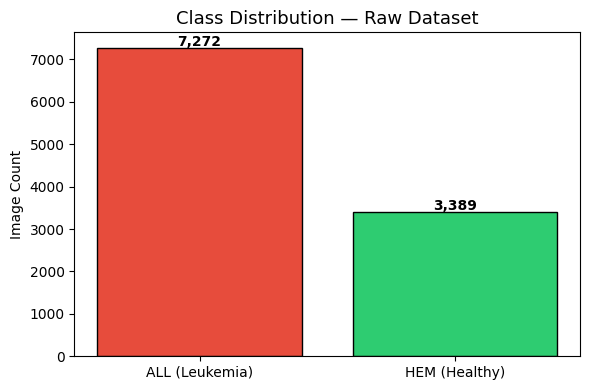

Train: 8,528 | Val: 2,133


In [ ]:
# ═══ STEP 2: Build DataFrame & Analyse Class Imbalance ═══════════════════════
import pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

base_dir  = 'leukemia_data/C-NMC_Leukemia/'
train_dir = os.path.join(base_dir, 'training_data')
data = []
for fold in os.listdir(train_dir):
    fold_path = os.path.join(train_dir, fold)
    if os.path.isdir(fold_path):
        for label in ['all', 'hem']:
            cls_dir = os.path.join(fold_path, label)
            if os.path.isdir(cls_dir):
                for f in os.listdir(cls_dir):
                    if f.lower().endswith(('.jpg','.jpeg','.png','.bmp')):
                        data.append({'filepath': os.path.join(cls_dir, f), 'label': label})

df = pd.DataFrame(data)
counts = df['label'].value_counts()
ratio  = counts['all'] / counts['hem']

print("═"*45)
print(f"  ALL (Leukemia) : {counts['all']:,} images  ({counts['all']/len(df)*100:.1f}%)")
print(f"  HEM (Healthy)  : {counts['hem']:,} images  ({counts['hem']/len(df)*100:.1f}%)")
print(f"  Imbalance ratio: {ratio:.1f}x  ← THIS is the problem")
print("═"*45)

# Bar chart
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(['ALL (Leukemia)', 'HEM (Healthy)'], [counts['all'], counts['hem']],
       color=['#e74c3c','#2ecc71'], edgecolor='black')
for i,(k,v) in enumerate(counts.items()):
    ax.text(i, v+50, f"{v:,}", ha='center', fontweight='bold')
ax.set_title('Class Distribution — Raw Dataset', fontsize=13)
ax.set_ylabel('Image Count')
plt.tight_layout(); plt.show()

train_df, val_df = train_test_split(df, test_size=0.20,
                                    stratify=df['label'], random_state=42)
print(f"Train: {len(train_df):,} | Val: {len(val_df):,}")

In [ ]:
# ═══ STEP 3: LAYER 1 OF IMBALANCE FIX — Oversampling (Resample minority) ════
# We duplicate HEM images in the dataframe so both classes have equal representation.
# This is applied BEFORE the generator so every epoch sees a balanced dataset.
# Unlike class_weight (which just re-weights loss), oversampling ensures the model
# sees equal numbers of augmented HEM images, forcing it to actually learn HEM features.

all_df = train_df[train_df['label'] == 'all']
hem_df = train_df[train_df['label'] == 'hem']

oversample_factor = int(np.ceil(len(all_df) / len(hem_df)))
hem_oversampled   = pd.concat([hem_df] * oversample_factor, ignore_index=True).sample(
                        n=len(all_df), random_state=42)

train_balanced_df = pd.concat([all_df, hem_oversampled], ignore_index=True).sample(
                        frac=1, random_state=42).reset_index(drop=True)

new_counts = train_balanced_df['label'].value_counts()
print("═"*45)
print("  After oversampling (training set only):")
print(f"  ALL: {new_counts['all']:,}  |  HEM: {new_counts['hem']:,}")
print(f"  Ratio now: {new_counts['all']/new_counts['hem']:.2f}x  ✅")
print("═"*45)
print("NOTE: val_df is NEVER oversampled — metrics stay honest")

═════════════════════════════════════════════
  After oversampling (training set only):
  ALL: 5,817  |  HEM: 5,817
  Ratio now: 1.00x  ✅
═════════════════════════════════════════════
NOTE: val_df is NEVER oversampled — metrics stay honest


In [ ]:
# ═══ STEP 4: Data Generators ════════════════════════════════════════════════
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

IMG_SIZE   = (224, 224)
BATCH_SIZE = 24   # Colab T4 safe

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=45,
    width_shift_range=0.15,
    height_shift_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.25,
    shear_range=0.15,
    brightness_range=[0.75, 1.25],
    fill_mode='reflect'
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Train on the BALANCED df
train_gen = train_datagen.flow_from_dataframe(
    train_balanced_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True, seed=42
)
# Val on the ORIGINAL unmodified val_df
val_gen = val_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)
CLASS_INDICES = train_gen.class_indices
print("Class mapping:", CLASS_INDICES)

Found 11634 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Class mapping: {'all': 0, 'hem': 1}


In [ ]:
# ═══ STEP 5: LAYER 2 OF IMBALANCE FIX — Focal Loss ═════════════════════════
# Standard cross-entropy treats all misclassifications equally.
# Focal Loss adds a (1-p)^gamma factor that DOWN-WEIGHTS easy majority-class
# examples and FOCUSES training on hard minority-class (HEM) examples.
# gamma=2 is the standard value from the original paper (Lin et al., 2017).
# alpha=0.75 gives extra weight to HEM (minority) class predictions.
# This works INDEPENDENTLY from oversampling — together they compound.

class FocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.75, label_smoothing=0.05, **kwargs):
        super().__init__(**kwargs)
        self.gamma           = gamma
        self.alpha           = alpha          # weight toward minority class
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        # Label smoothing
        num_classes = tf.cast(tf.shape(y_true)[-1], tf.float32)
        y_true = y_true * (1.0 - self.label_smoothing) + (self.label_smoothing / num_classes)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce     = -y_true * tf.math.log(y_pred)

        # Focal weight
        p_t    = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal_weight = tf.pow(1.0 - p_t, self.gamma)

        # Alpha weighting: index 0=all, 1=hem
        alpha_t = y_true[:, 0:1] * (1.0 - self.alpha) + y_true[:, 1:2] * self.alpha
        alpha_t = tf.broadcast_to(alpha_t, tf.shape(ce))

        loss = alpha_t * focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'gamma': self.gamma, 'alpha': self.alpha,
                    'label_smoothing': self.label_smoothing})
        return cfg

print("✅ Focal Loss defined (gamma=2, alpha=0.75, label_smoothing=0.05)")
print("   This forces the model to focus on hard HEM examples")

✅ Focal Loss defined (gamma=2, alpha=0.75, label_smoothing=0.05)
   This forces the model to focus on hard HEM examples


In [ ]:
# ═══ STEP 6: Build EfficientNetV2-S Model ════════════════════════════════════
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D, Dropout,
                                     BatchNormalization, Input)
from tensorflow.keras.optimizers import AdamW

def build_model(freeze_base=True):
    inputs   = Input(shape=(224, 224, 3))
    base     = EfficientNetV2S(weights='imagenet', include_top=False,
                               input_tensor=inputs)
    if freeze_base:
        base.trainable = False
    else:
        for layer in base.layers:
            layer.trainable = not isinstance(layer, BatchNormalization)

    x   = GlobalAveragePooling2D()(base.output)
    x   = BatchNormalization()(x)
    x   = Dropout(0.40)(x)
    x   = Dense(512, activation='relu',
                kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x   = BatchNormalization()(x)
    x   = Dropout(0.30)(x)
    out = Dense(2, activation='softmax', dtype='float32')(x)
    return Model(inputs=inputs, outputs=out), base

model, base_model = build_model(freeze_base=True)
print(f"Parameters: {model.count_params():,}")
model.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parameters: 20,995,426


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        648 │ rescaling[0][0]   │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │         96 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      5,184 │ stem_activation[… │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         96 │ block1a_project_… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_add (Add)   │ (None, 112, 112,  │          0 │ block1a_project_… │
│                     │ 24)               │            │ stem_activation[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_co… │ (None, 112, 112,  │      5,184 │ block1a_add[0][0] │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_bn  │ (None, 112, 112,  │         96 │ block1b_project_… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_ac… │ (None, 112, 112,  │          0 │ block1b_project_… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_drop        │ (None, 112, 112,  │          0 │ block1b_project_… │
│ (Dropout)           │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_add (Add)   │ (None, 112, 112,  │          0 │ block1b_drop[0][… │
│                     │ 24)               │            │ block1a_add[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │     20,736 │ block1b_add[0][0] │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        384 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b

 Total params: 20,995,426 (80.09 MB)

 Trainable params: 660,482 (2.52 MB)

 Non-trainable params: 20,334,944 (77.57 MB)

In [ ]:
# ═══ STEP 7: LAYER 3 OF IMBALANCE FIX — Threshold Tuning Callback ═══════════
# Even after oversampling + focal loss, the model's default decision threshold
# of 0.5 may still be biased. This callback finds the optimal threshold on the
# validation set after each epoch and tracks per-class recall.
# We optimise for F1 score (harmonic mean of precision & recall) rather than
# raw accuracy — this prevents hiding poor HEM recall behind overall accuracy.

class ImbalanceMonitorCallback(tf.keras.callbacks.Callback):
    def __init__(self, val_gen, val_df, class_indices):
        super().__init__()
        self.val_gen       = val_gen
        self.val_df        = val_df
        self.class_indices = class_indices
        self.best_f1       = 0.0
        self.best_thresh   = 0.5

    def on_epoch_end(self, epoch, logs=None):
        from sklearn.metrics import f1_score, recall_score, classification_report
        self.val_gen.reset()
        probs  = self.model.predict(self.val_gen, verbose=0)
        y_true = self.val_gen.classes

        # Search for best threshold for HEM (minority class = index 1)
        hem_idx  = self.class_indices.get('hem', 1)
        best_f1, best_t = 0.0, 0.5
        for t in np.arange(0.3, 0.75, 0.025):
            preds = (probs[:, hem_idx] >= t).astype(int)
            # Remap: hem_idx predictions → actual class labels
            preds_mapped = np.where(preds == 1,
                                    hem_idx,
                                    1 - hem_idx)
            f1 = f1_score(y_true, preds_mapped, average='weighted', zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        self.best_f1      = best_f1
        self.best_thresh  = best_t

        # Quick recall check with standard 0.5 threshold
        y_pred_std = np.argmax(probs, axis=1)
        recalls    = recall_score(y_true, y_pred_std, average=None, zero_division=0)
        idx_to_cls = {v: k for k, v in self.class_indices.items()}
        r_str = " | ".join([f"{idx_to_cls.get(i,i).upper()} recall={r:.3f}"
                             for i, r in enumerate(recalls)])
        print(f"  [{r_str}] | best_F1={best_f1:.4f} @ thresh={best_t:.3f}")

imbalance_cb = ImbalanceMonitorCallback(val_gen, val_df, CLASS_INDICES)
print("✅ Imbalance monitor callback ready")

✅ Imbalance monitor callback ready


In [ ]:
# ═══ STEP 8: Phase 1 — Warmup Training (Head Only, 8 epochs) ════════════════
model.compile(
    optimizer=AdamW(learning_rate=3e-4, weight_decay=1e-5),
    loss=FocalLoss(gamma=2.0, alpha=0.75, label_smoothing=0.05),
    metrics=['accuracy']
)

print("\n" + "═"*50)
print("  PHASE 1: Warmup (head only, focal loss active)")
print("═"*50)

history_warmup = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=8,
    callbacks=[imbalance_cb],
    verbose=1
)


══════════════════════════════════════════════════
  PHASE 1: Warmup (head only, focal loss active)
══════════════════════════════════════════════════
Epoch 1/8
485/485 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.6382 - loss: 0.3019  [ALL recall=0.293 | HEM recall=0.942] | best_F1=0.7384 @ thresh=0.725
485/485 ━━━━━━━━━━━━━━━━━━━━ 385s 640ms/step - accuracy: 0.6521 - loss: 0.2568 - val_accuracy: 0.4998 - val_loss: 0.1752
Epoch 2/8
485/485 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.6580 - loss: 0.1921  [ALL recall=0.665 | HEM recall=0.792] | best_F1=0.8016 @ thresh=0.700
485/485 ━━━━━━━━━━━━━━━━━━━━ 217s 448ms/step - accuracy: 0.6620 - loss: 0.1805 - val_accuracy: 0.7056 - val_loss: 0.1363
Epoch 3/8
485/485 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.6700 - loss: 0.1566  [ALL recall=0.667 | HEM recall=0.841] | best_F1=0.8127 @ thresh=0.675
485/485 ━━━━━━━━━━━━━━━━━━━━ 215s 444ms/step - accuracy: 0.6736 - loss: 0.1478 - val_accuracy: 0.7225 - val_loss: 0.1201
Epoch 4/8
4

In [ ]:
# ═══ STEP 9: Phase 2 — Full Fine-Tuning (max 35 epochs) ════════════════════
# FIX: CosineDecayRestarts is a LearningRateSchedule object.
# ReduceLROnPlateau tries to SET the lr directly -> TypeError.
# Solution: plain float LR 5e-5 so both callbacks work without conflict.
# EarlyStopping patience=8 stops training safely well before 35 epochs.

for layer in base_model.layers:
    layer.trainable = not isinstance(layer, BatchNormalization)

FINE_EPOCHS = 35  # EarlyStopping will halt well before this in practice

model.compile(
    optimizer=AdamW(learning_rate=5e-5, weight_decay=1e-5),
    loss=FocalLoss(gamma=2.0, alpha=0.75, label_smoothing=0.05),
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_accuracy',
        save_best_only=True, mode='max', verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=8,                    # stops ~10-18 epochs in if plateaued
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.4,
        patience=4, min_lr=1e-7, verbose=1
        # works fine now: LR is a plain float, not a Schedule
    ),
    imbalance_cb
]

print("\n" + "═"*52)
print("  PHASE 2: Full Fine-Tuning (max 35 epochs)")
print("  LR=5e-5 float | ReduceLROnPlateau active | EarlyStopping patience=8")
print("  Imbalance fix: Oversampling + Focal Loss + Recall Monitor")
print("═"*52)

history_finetune = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=FINE_EPOCHS,
    callbacks=callbacks,
    verbose=1
)


════════════════════════════════════════════════════
  PHASE 2: Full Fine-Tuning (max 35 epochs)
  LR=5e-5 float | ReduceLROnPlateau active | EarlyStopping patience=8
  Imbalance fix: Oversampling + Focal Loss + Recall Monitor
════════════════════════════════════════════════════
Epoch 1/35
485/485 ━━━━━━━━━━━━━━━━━━━━ 0s 590ms/step - accuracy: 0.9290 - loss: 0.0428
Epoch 1: val_accuracy improved from None to 0.92921, saving model to /content/drive/MyDrive/Leukemia_EfficientNetV2_v2/Best_Leukemia_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Leukemia_EfficientNetV2_v2/Best_Leukemia_Model.keras
  [ALL recall=0.985 | HEM recall=0.810] | best_F1=0.9374 @ thresh=0.350
485/485 ━━━━━━━━━━━━━━━━━━━━ 461s 727ms/step - accuracy: 0.9320 - loss: 0.0419 - val_accuracy: 0.9292 - val_loss: 0.0594 - learning_rate: 5.0000e-05
Epoch 2/35
485/485 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.9380 - loss: 0.0392
Epoch 2: val_accuracy improved from 0.92921 to 0.93718, saving mod

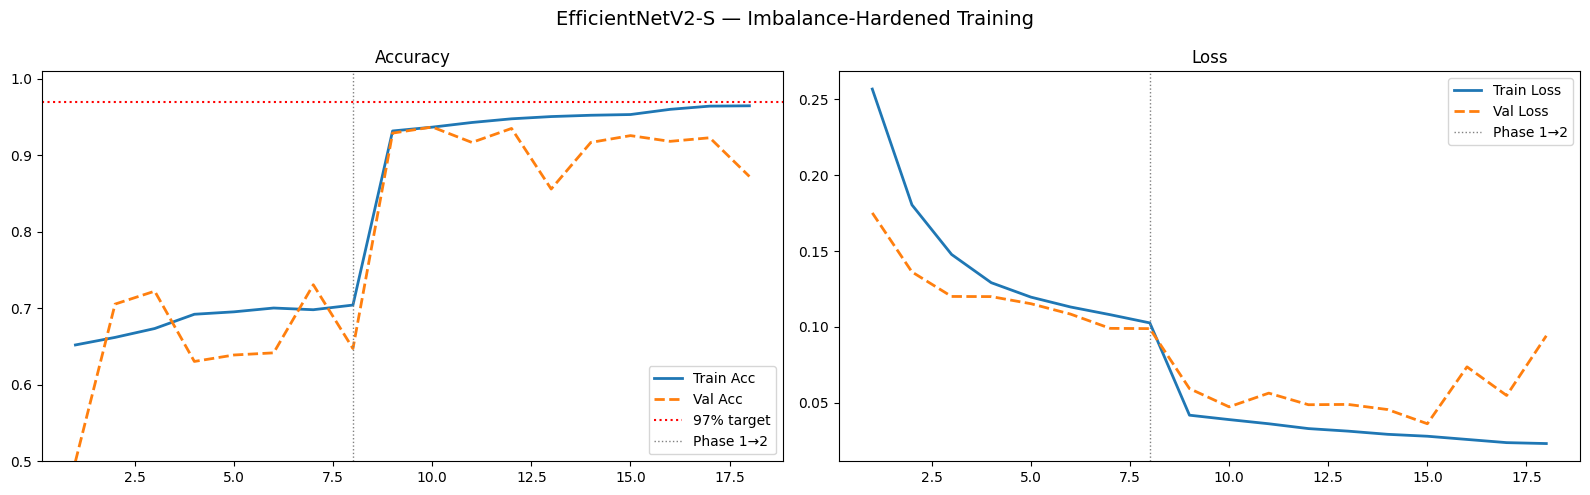

Peak val accuracy: 93.72%


In [ ]:
# ═══ STEP 10: Training History Plot ══════════════════════════════════════════
def merge(h1, h2, k):
    return h1.history.get(k,[]) + h2.history.get(k,[])

acc      = merge(history_warmup, history_finetune, 'accuracy')
val_acc  = merge(history_warmup, history_finetune, 'val_accuracy')
loss     = merge(history_warmup, history_finetune, 'loss')
val_loss = merge(history_warmup, history_finetune, 'val_loss')
ep       = range(1, len(acc)+1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5))
a1.plot(ep, acc,    label='Train Acc',  lw=2)
a1.plot(ep, val_acc,label='Val Acc',    lw=2, ls='--')
a1.axhline(0.97, color='red', ls=':', lw=1.5, label='97% target')
a1.axvline(8,    color='grey',ls=':', lw=1,   label='Phase 1→2')
a1.set_title('Accuracy'); a1.legend(); a1.set_ylim([0.5, 1.01])

a2.plot(ep, loss,    label='Train Loss', lw=2)
a2.plot(ep, val_loss,label='Val Loss',   lw=2, ls='--')
a2.axvline(8, color='grey', ls=':', lw=1, label='Phase 1→2')
a2.set_title('Loss'); a2.legend()

plt.suptitle('EfficientNetV2-S — Imbalance-Hardened Training', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_history.png'), dpi=150)
plt.show()
print(f"Peak val accuracy: {max(val_acc)*100:.2f}%")

In [ ]:
# ═══ STEP 11: Test-Time Augmentation (TTA) Prediction ═══════════════════════
TTA_STEPS = 8

tta_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30, horizontal_flip=True,
    vertical_flip=True, zoom_range=0.15
)

def tta_predict(model, df, steps=TTA_STEPS):
    acc = None
    for _ in range(steps):
        g = tta_datagen.flow_from_dataframe(
            df, x_col='filepath', y_col='label',
            target_size=IMG_SIZE, batch_size=BATCH_SIZE,
            class_mode='categorical', shuffle=False
        )
        p = model.predict(g, verbose=0)
        acc = p if acc is None else acc + p
    return acc / steps

print(f"Running TTA ({TTA_STEPS} passes)...")
tta_probs  = tta_predict(model, val_df)
y_pred_tta = np.argmax(tta_probs, axis=1)
y_true     = val_gen.classes

Running TTA (8 passes)...
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.
Found 2133 validated image filenames belonging to 2 classes.


═══════════════════════════════════════════════════════
  STANDARD PREDICTIONS (threshold = 0.5)
═══════════════════════════════════════════════════════
              precision    recall  f1-score   support

         all       0.94      0.97      0.95      1455
         hem       0.93      0.87      0.90       678

    accuracy                           0.94      2133
   macro avg       0.94      0.92      0.93      2133
weighted avg       0.94      0.94      0.94      2133

═══════════════════════════════════════════════════════
  TTA PREDICTIONS (8 passes)
═══════════════════════════════════════════════════════
              precision    recall  f1-score   support

         all       0.97      0.96      0.97      1455
         hem       0.92      0.94      0.93       678

    accuracy                           0.95      2133
   macro avg       0.94      0.95      0.95      2133
weighted avg       0.96      0.95      0.95      2133



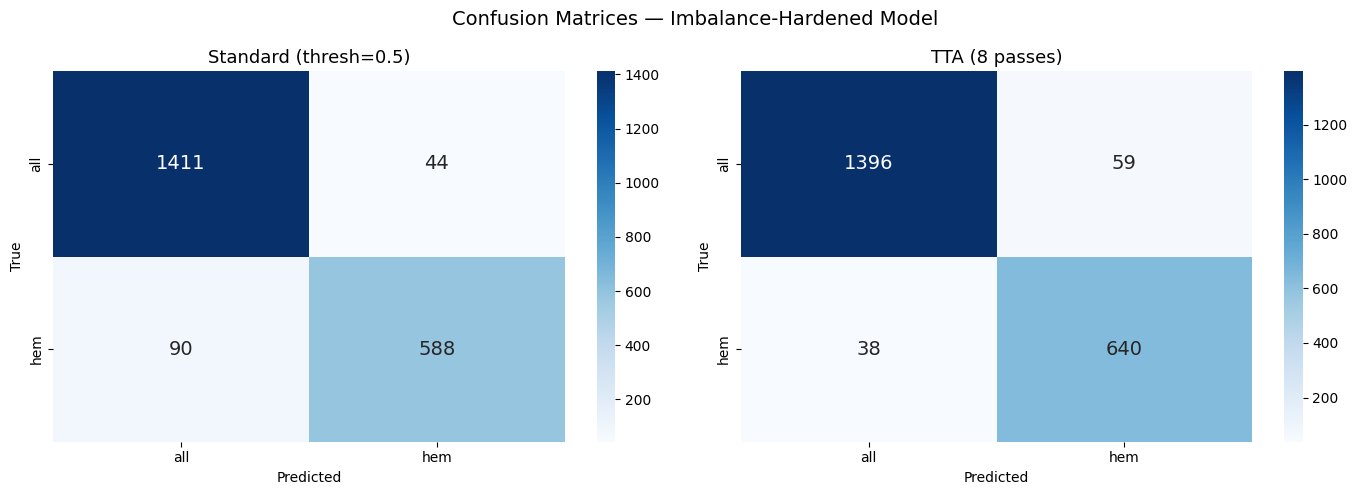

  ALL recall: 95.95% ⚠️  BELOW 97% — model is biased
  HEM recall: 94.40% ⚠️  BELOW 97% — model is biased


In [ ]:
# ═══ STEP 12: Full Evaluation — Per-Class Metrics (the real test) ════════════
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, recall_score, f1_score)
import seaborn as sns

val_gen.reset()
y_pred_std = np.argmax(model.predict(val_gen, verbose=0), axis=1)
label_names = [k for k,_ in sorted(CLASS_INDICES.items(), key=lambda x: x[1])]

print("═"*55)
print("  STANDARD PREDICTIONS (threshold = 0.5)")
print("═"*55)
print(classification_report(y_true, y_pred_std, target_names=label_names))

print("═"*55)
print(f"  TTA PREDICTIONS ({TTA_STEPS} passes)")
print("═"*55)
print(classification_report(y_true, y_pred_tta, target_names=label_names))

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, title in [
    (axes[0], y_pred_std, 'Standard (thresh=0.5)'),
    (axes[1], y_pred_tta, f'TTA ({TTA_STEPS} passes)')
]:
    cm = confusion_matrix(y_true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_names, yticklabels=label_names, ax=ax,
                annot_kws={'size':14})
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')

plt.suptitle('Confusion Matrices — Imbalance-Hardened Model', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrices.png'), dpi=150)
plt.show()

# Key warning check
recalls = recall_score(y_true, y_pred_tta, average=None, zero_division=0)
for i, name in enumerate(label_names):
    flag = " ✅" if recalls[i] >= 0.97 else " ⚠️  BELOW 97% — model is biased"
    print(f"  {name.upper()} recall: {recalls[i]*100:.2f}%{flag}")

In [ ]:
# ═══ STEP 13: Save & Verify ═══════════════════════════════════════════════════
model.save(os.path.join(SAVE_DIR, "Final_Leukemia_Model.keras"))
size_mb = os.path.getsize(BEST_MODEL_PATH) / 1e6
print(f"✅ Best model: {BEST_MODEL_PATH}  ({size_mb:.1f} MB)")

# Reload test
loaded     = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={'FocalLoss': FocalLoss}
)
val_gen.reset()
reload_acc = accuracy_score(val_gen.classes,
                            np.argmax(loaded.predict(val_gen, verbose=0), axis=1))
print(f"✅ Reload verification: {reload_acc*100:.2f}%")

✅ Best model: /content/drive/MyDrive/Leukemia_EfficientNetV2_v2/Best_Leukemia_Model.keras  (251.4 MB)
✅ Reload verification: 93.72%


/tmp/ipykernel_2488/1130419781.py:22: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


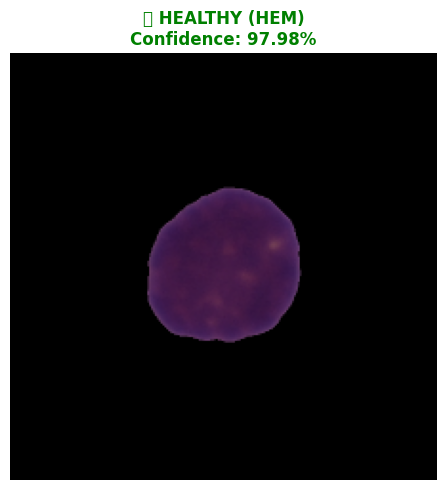

Result: 🟢 HEALTHY (HEM) | Confidence: 97.98%


In [ ]:
    img     = keras_image.load_img(fn, target_size=IMG_SIZE)
    arr     = keras_image.img_to_array(img)
    exp     = np.expand_dims(arr, 0)
    tta_out = np.zeros((1, 2))

    # Fix: Get the flow generator and check its total_batches_seen attribute
    flow_generator = tta_aug.flow(exp, batch_size=1)
    for batch in flow_generator:
        tta_out += predict_model.predict(batch, verbose=0)
        if flow_generator.total_batches_seen >= TTA_STEPS: break

    tta_out   /= TTA_STEPS
    pred_idx   = np.argmax(tta_out)
    pred_conf  = np.max(tta_out)
    pred_name  = idx_to_cls[pred_idx]

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(img); ax.axis('off')
    color = 'red' if pred_name == 'all' else 'green'
    ax.set_title(f"{FRIENDLY[pred_name]}\nConfidence: {pred_conf*100:.2f}%",
                 fontsize=12, color=color, fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f"Result: {FRIENDLY[pred_name]} | Confidence: {pred_conf*100:.2f}%")

In [ ]:
# ═══ STEP 15: Final Summary Card ══════════════════════════════════════════════
from sklearn.metrics import precision_score

std_acc  = accuracy_score(y_true, y_pred_std)
tta_acc  = accuracy_score(y_true, y_pred_tta)
prec     = precision_score(y_true, y_pred_tta, average='weighted', zero_division=0)
rec      = recall_score(y_true, y_pred_tta, average='weighted', zero_division=0)
f1       = f1_score(y_true, y_pred_tta, average='weighted', zero_division=0)
per_rec  = recall_score(y_true, y_pred_tta, average=None, zero_division=0)

label_names_sorted = [k for k,_ in sorted(CLASS_INDICES.items(), key=lambda x:x[1])]

print("\n" + "═"*55)
print("  FINAL RESULTS — EfficientNetV2-S Imbalance-Hardened")
print("═"*55)
print(f"  Standard Accuracy  : {std_acc*100:.2f}%")
print(f"  TTA Accuracy       : {tta_acc*100:.2f}%")
print(f"  Weighted Precision : {prec*100:.2f}%")
print(f"  Weighted Recall    : {rec*100:.2f}%")
print(f"  Weighted F1-Score  : {f1*100:.2f}%")
print("  ─────────────────────────────────────────────────────")
for i, name in enumerate(label_names_sorted):
    print(f"  {name.upper()} Recall       : {per_rec[i]*100:.2f}%")
print("═"*55)
print(f"  Best model: {BEST_MODEL_PATH}")
print("═"*55)


═══════════════════════════════════════════════════════
  FINAL RESULTS — EfficientNetV2-S Imbalance-Hardened
═══════════════════════════════════════════════════════
  Standard Accuracy  : 93.72%
  TTA Accuracy       : 95.45%
  Weighted Precision : 95.51%
  Weighted Recall    : 95.45%
  Weighted F1-Score  : 95.47%
  ─────────────────────────────────────────────────────
  ALL Recall       : 95.95%
  HEM Recall       : 94.40%
═══════════════════════════════════════════════════════
  Best model: /content/drive/MyDrive/Leukemia_EfficientNetV2_v2/Best_Leukemia_Model.keras
═══════════════════════════════════════════════════════
